In [ ]:
from google.colab import files
files.download("books_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Summary statistics
print("DATASET SUMMARY")
print("=" * 35)

print("Total books:", len(df))
print(f"Average price: £{df['Price_numeric'].mean():.2f}")
print(f"Lowest price: £{df['Price_numeric'].min():.2f}")
print(f"Highest price: £{df['Price_numeric'].max():.2f}")

print("\nBooks by rating:")
print(df["Rating"].value_counts())

print("\nFive cheapest books:")
display(
    df.sort_values("Price_numeric")[
        ["Title", "Price", "Rating"]
    ].head(5)
)

DATASET SUMMARY
Total books: 100
Average price: £34.56
Lowest price: £10.16
Highest price: £58.11

Books by rating:
Rating
Three    22
One      22
Five     19
Two      19
Four     18
Name: count, dtype: int64

Five cheapest books:


,Title,Price,Rating
84,Patience,£10.16,Three
20,In Her Wake,£12.84,One
81,Princess Between Worlds (Wide-Awake Princess #5),£13.34,Five
80,"Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Pr...",£13.61,Five
10,"Starving Hearts (Triangular Trade Trilogy, #1)",£13.99,Two


In [ ]:
from google.colab import files

files.download("books_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import requests
import pandas as pd
import time
from bs4 import BeautifulSoup
from urllib.parse import urljoin

base_url = "https://books.toscrape.com/"
next_url = urljoin(base_url, "catalogue/page-1.html")

all_books = []
max_pages = 5

for page in range(1, max_pages + 1):
    print(f"Scraping page {page}...")

    response = requests.get(next_url, timeout=20)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")
    listings = soup.select("article.product_pod")

    if not listings:
        print("No book listings found. Stopping.")
        break

    for book in listings:
        title_tag = book.select_one("h3 a")
        price_tag = book.select_one(".price_color")
        rating_tag = book.select_one(".star-rating")
        availability_tag = book.select_one(".availability")

        if title_tag is None or price_tag is None:
            continue

        rating_classes = rating_tag.get("class", []) if rating_tag else []
        rating = next(
            (c for c in rating_classes if c != "star-rating"),
            "Unknown"
        )

        price = price_tag.get_text(strip=True).replace("Â£", "£")

        all_books.append({
            "Title": title_tag.get("title", title_tag.get_text(strip=True)),
            "Price": price,
            "Rating": rating,
            "Availability": (
                availability_tag.get_text(" ", strip=True)
                if availability_tag else "Unknown"
            ),
            "Book_URL": urljoin(next_url, title_tag.get("href", ""))
        })

    next_link = soup.select_one("li.next a")

    if not next_link:
        break

    next_url = urljoin(next_url, next_link["href"])
    time.sleep(1)

df = pd.DataFrame(all_books)
df = df.drop_duplicates(subset=["Title"]).reset_index(drop=True)

df["Price_numeric"] = pd.to_numeric(
    df["Price"].str.replace("£", "", regex=False),
    errors="coerce"
)

df.to_csv("books_dataset.csv", index=False, encoding="utf-8-sig")

print("\nScraping completed!")
print("Total unique books:", len(df))
print("Missing values per column:")
print(df.isnull().sum())
print("\nFirst five records:")
display(df.head())

Scraping page 1...
Scraping page 2...
Scraping page 3...
Scraping page 4...
Scraping page 5...

Scraping completed!
Total unique books: 100
Missing values per column:
Title            0
Price            0
Rating           0
Availability     0
Book_URL         0
Price_numeric    0
dtype: int64

First five records:


,Title,Price,Rating,Availability,Book_URL,Price_numeric
0,A Light in the Attic,£51.77,Three,In stock,https://books.toscrape.com/catalogue/a-light-i...,51.77
1,Tipping the Velvet,£53.74,One,In stock,https://books.toscrape.com/catalogue/tipping-t...,53.74
2,Soumission,£50.10,One,In stock,https://books.toscrape.com/catalogue/soumissio...,50.10
3,Sharp Objects,£47.82,Four,In stock,https://books.toscrape.com/catalogue/sharp-obj...,47.82
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock,https://books.toscrape.com/catalogue/sapiens-a...,54.23


In [ ]:
import pandas as pd
from urllib.parse import urljoin

books_data = []

for book in book_list:
    title = book.select_one("h3 a")["title"]

    price = book.select_one(".price_color").get_text(strip=True)
    price = price.replace("Â£", "£")

    availability = book.select_one(
        ".availability"
    ).get_text(" ", strip=True)

    rating_tag = book.select_one(".star-rating")
    rating = rating_tag.get("class", ["", "Unknown"])[1]

    link = book.select_one("h3 a")["href"]
    book_url = urljoin(url, link)

    books_data.append({
        "Title": title,
        "Price": price,
        "Rating": rating,
        "Availability": availability,
        "Book_URL": book_url
    })

df = pd.DataFrame(books_data)

df.to_csv("books_dataset.csv", index=False, encoding="utf-8-sig")

print("Dataset created successfully!")
print("Total records:", len(df))
print("\nDataset preview:")
display(df.head())

Dataset created successfully!
Total records: 20

Dataset preview:


,Title,Price,Rating,Availability,Book_URL
0,A Light in the Attic,£51.77,Three,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,£53.74,One,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,£50.10,One,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,£47.82,Four,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock,https://books.toscrape.com/catalogue/sapiens-a...


In [ ]:
from bs4 import BeautifulSoup

soup = BeautifulSoup(response.text, "html.parser")

book_list = soup.select("article.product_pod")

print("Total books found:", len(book_list))
print("\nFirst 5 books:\n")

for book in book_list[:5]:
    title = book.select_one("h3 a")["title"]
    price = book.select_one(".price_color").get_text(strip=True)
    availability = book.select_one(".availability").get_text(strip=True)

    rating_tag = book.select_one(".star-rating")
    rating = rating_tag.get("class")[1]

    print("Title:", title)
    print("Price:", price)
    print("Rating:", rating)
    print("Availability:", availability)
    print("-" * 40)

Total books found: 20

First 5 books:

Title: A Light in the Attic
Price: Â£51.77
Rating: Three
Availability: In stock
----------------------------------------
Title: Tipping the Velvet
Price: Â£53.74
Rating: One
Availability: In stock
----------------------------------------
Title: Soumission
Price: Â£50.10
Rating: One
Availability: In stock
----------------------------------------
Title: Sharp Objects
Price: Â£47.82
Rating: Four
Availability: In stock
----------------------------------------
Title: Sapiens: A Brief History of Humankind
Price: Â£54.23
Rating: Five
Availability: In stock
----------------------------------------


In [ ]:
import requests
url = "https://books.toscrape.com/"
response = requests.get(url, timeout=20)

print("Status code:", response.status_code)
print("website connected successfully!")
print("HTML length:", len(response.text))

Status code: 200
website connected successfully!
HTML length: 51294


In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

print("All libraries are working!")
print("Request version:", requests.__version__)
print("Pandas version:", pd.__version__)

All libraries are working!
Request version: 2.32.4
Pandas version: 2.2.3


In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

In [ ]:
import sys
!{sys.executable} -m pip install requests beautifulsoup4 pandas

In [ ]:
# 1. Check the size of the dataset
print("DATASET SHAPE")
print("Rows and columns:", df.shape)

# 2. Inspect the column names and data types
print("\nDATASET INFORMATION")
df.info()

# 3. Check for missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# 4. Check for duplicate records
print("\nDUPLICATE ROWS")
print("Duplicates:", df.duplicated().sum())

# 5. View statistical summaries
print("\nNUMERICAL SUMMARY")
display(df.describe())

# 6. View the first five records
print("\nFIRST FIVE RECORDS")
display(df.head())

DATASET SHAPE
Rows and columns: (100, 6)

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Title          100 non-null    object 
 1   Price          100 non-null    object 
 2   Rating         100 non-null    object 
 3   Availability   100 non-null    object 
 4   Book_URL       100 non-null    object 
 5   Price_numeric  100 non-null    float64
dtypes: float64(1), object(5)
memory usage: 4.8+ KB

MISSING VALUES
Title            0
Price            0
Rating           0
Availability     0
Book_URL         0
Price_numeric    0
dtype: int64

DUPLICATE ROWS
Duplicates: 0

NUMERICAL SUMMARY


,Price_numeric
count,100.000000
mean,34.560700
std,14.638531
min,10.160000
25%,19.897500
50%,34.775000
75%,47.967500
max,58.110000



FIRST FIVE RECORDS


,Title,Price,Rating,Availability,Book_URL,Price_numeric
0,A Light in the Attic,£51.77,Three,In stock,https://books.toscrape.com/catalogue/a-light-i...,51.77
1,Tipping the Velvet,£53.74,One,In stock,https://books.toscrape.com/catalogue/tipping-t...,53.74
2,Soumission,£50.10,One,In stock,https://books.toscrape.com/catalogue/soumissio...,50.10
3,Sharp Objects,£47.82,Four,In stock,https://books.toscrape.com/catalogue/sharp-obj...,47.82
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock,https://books.toscrape.com/catalogue/sapiens-a...,54.23


In [15]:
# Check dataset size
print("Dataset shape:", df.shape)

# Check data types
print("\nColumn data types:")
print(df.dtypes)

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check duplicate book titles
print("Duplicate titles:", df["Title"].duplicated().sum())

# Check unique ratings
print("\nRatings found:")
print(df["Rating"].value_counts())

Dataset shape: (100, 6)

Column data types:
Title             object
Price             object
Rating            object
Availability      object
Book_URL          object
Price_numeric    float64
dtype: object

Duplicate rows: 0
Duplicate titles: 0

Ratings found:
Rating
Three    22
One      22
Five     19
Two      19
Four     18
Name: count, dtype: int64


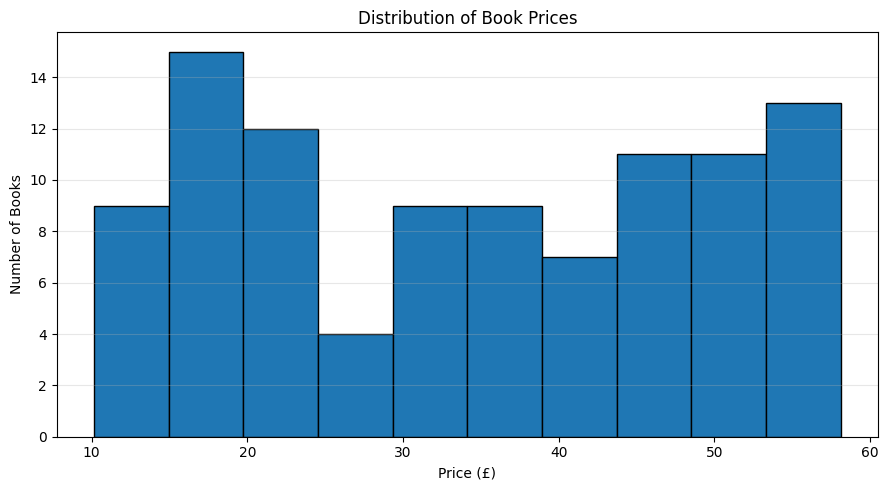

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    df["Price_numeric"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

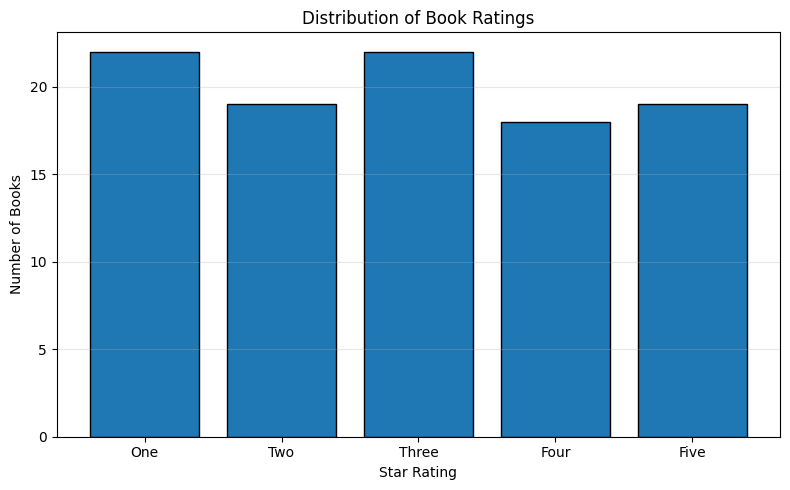

Rating counts:
Rating
One      22
Two      19
Three    22
Four     18
Five     19
Name: count, dtype: int64


In [17]:
import matplotlib.pyplot as plt

rating_order = ["One", "Two", "Three", "Four", "Five"]

rating_counts = (
    df["Rating"]
    .value_counts()
    .reindex(rating_order, fill_value=0)
)

plt.figure(figsize=(8, 5))
plt.bar(rating_counts.index, rating_counts.values,
        edgecolor="black")

plt.title("Distribution of Book Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Rating counts:")
print(rating_counts)

In [18]:
import pandas as pd
from scipy.stats import kruskal

# Research question:
# Do prices differ across book-rating groups?

rating_order = ["One", "Two", "Three", "Four", "Five"]

# Prepare the price data for each rating group
groups = [
    df.loc[df["Rating"] == rating, "Price_numeric"].dropna()
    for rating in rating_order
]

# Display group summaries
print("PRICE SUMMARY BY RATING")
summary = df.groupby("Rating")["Price_numeric"].agg(
    ["count", "mean", "median", "std"]
).reindex(rating_order)

display(summary.round(2))

# Hypothesis test
H_stat, p_value = kruskal(*groups)

print("\nKRUSKAL-WALLIS TEST")
print(f"H-statistic: {H_stat:.4f}")
print(f"P-value: {p_value:.4f}")

alpha = 0.05

if p_value < alpha:
    print("Result: Statistically significant difference detected.")
else:
    print("Result: No statistically significant difference detected.")

print("Significance level:", alpha)

PRICE SUMMARY BY RATING


,count,mean,median,std
Rating,,,,
One,22,35.52,37.01,15.06
Two,19,35.91,37.32,13.72
Three,22,36.84,37.02,15.76
Four,18,33.98,35.75,15.10
Five,19,30.01,25.27,13.76



KRUSKAL-WALLIS TEST
H-statistic: 2.6655
P-value: 0.6153
Result: No statistically significant difference detected.
Significance level: 0.05


Q1: 19.9
Q3: 47.97
IQR: 28.07
Lower boundary: -22.21
Upper boundary: 90.07
Potential outliers: 0


,Title,Price,Rating


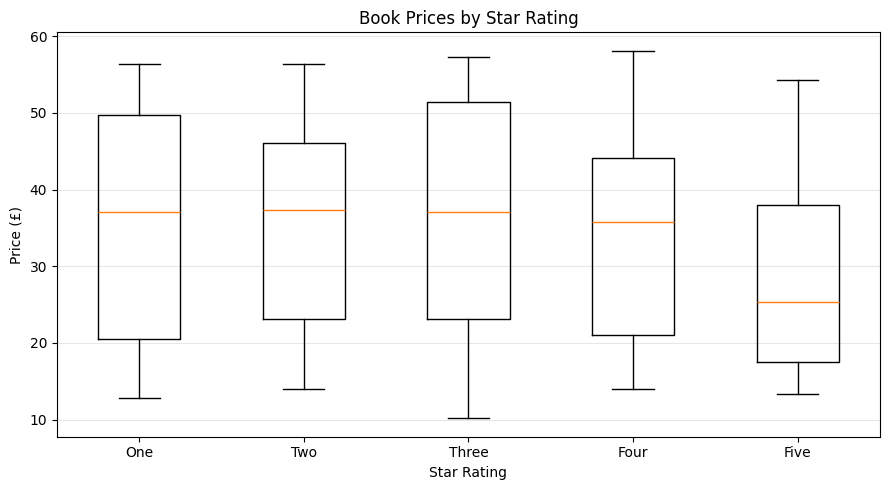

In [19]:
import matplotlib.pyplot as plt

# Calculate the interquartile range
Q1 = df["Price_numeric"].quantile(0.25)
Q3 = df["Price_numeric"].quantile(0.75)
IQR = Q3 - Q1

# Calculate potential outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify potential outliers
outliers = df[
    (df["Price_numeric"] < lower_bound) |
    (df["Price_numeric"] > upper_bound)
]

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower boundary:", round(lower_bound, 2))
print("Upper boundary:", round(upper_bound, 2))
print("Potential outliers:", len(outliers))

display(outliers[["Title", "Price", "Rating"]])

# Visualize prices by rating
rating_order = ["One", "Two", "Three", "Four", "Five"]
price_groups = [
    df.loc[df["Rating"] == r, "Price_numeric"]
    for r in rating_order
]

plt.figure(figsize=(9, 5))
plt.boxplot(price_groups, tick_labels=rating_order)
plt.title("Book Prices by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Price (£)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
# Check for invalid prices
print("Prices zero or below:",
      (df["Price_numeric"] <= 0).sum())

# Check expected rating categories
valid_ratings = {"One", "Two", "Three", "Four", "Five"}
unexpected_ratings = set(df["Rating"].dropna()) - valid_ratings
print("Unexpected ratings:", unexpected_ratings)

# Check availability values
print("\nAvailability counts:")
print(df["Availability"].value_counts())

# Check for empty titles or URLs
print("\nEmpty titles:", df["Title"].isna().sum() +
      (df["Title"].astype(str).str.strip() == "").sum())
print("Empty URLs:", df["Book_URL"].isna().sum() +
      (df["Book_URL"].astype(str).str.strip() == "").sum())

# Final descriptive statistics
print("\nPrice statistics:")
display(df["Price_numeric"].describe().round(2))

Prices zero or below: 0
Unexpected ratings: set()

Availability counts:
Availability
In stock    100
Name: count, dtype: int64

Empty titles: 0
Empty URLs: 0

Price statistics:


,Price_numeric
count,100.00
mean,34.56
std,14.64
min,10.16
25%,19.90
50%,34.78
75%,47.97
max,58.11


In [21]:
from google.colab import files
files.download("books_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>